# Airline Sentiment Classification with a Recurrent Neural Network

Three-class sentiment classification (negative / neutral / positive) of US airline tweets, using a
stacked bidirectional LSTM with an attention mechanism.


## Setup

In [1]:
import sys
from pathlib import Path


project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
sys.path.insert(0, str(project_root))

import torch
import torch.nn as nn

from src.preprocessing import load_raw_data, preprocess_dataset
from src.sequences import encode_labels, split_data, build_sequence_features
from src.model import BiLSTMAttention
from src.train import set_seed, make_loaders, train_model
from src.evaluate import predict, plot_loss_curves, plot_confusion_matrix

set_seed()

## 1. Data

The cleaning pipeline includes:
 HTML entities are decoded, URLs and `@mentions`
are removed whole, contractions are expanded so negations survive, digits and emojis are dropped,
and `!` and `?` are kept because they carry sentiment. Duplicates are removed on the cleaned text.



In [2]:
df = preprocess_dataset(load_raw_data())
df, class_names = encode_labels(df)
train_df, val_df, test_df = split_data(df)

Loaded 14640 rows and 15 columns from Tweets.csv
Rows in            : 14640
Empty after cleaning: 0
Duplicates removed : 436
Rows out           : 14204
Label mapping: {'negative': 0, 'neutral': 1, 'positive': 2}
Train 11363 | Validation 1420 | Test 1421


### Turning words into padded index sequences


The vocabulary and the padding length are both derived from the **training split only** .


In [3]:
X_train, X_val, X_test, vocab, max_len = build_sequence_features(
    train_df["tokens"], val_df["tokens"], test_df["tokens"]
)

Training lengths: mean 17.4 | median 19 | p95 27 | max 37
Vocabulary: 5009 entries (min_count=2, including <pad> and <unk>)
train       (11363, 27) | truncated 418 tweets (3.7%) | unknown tokens 2.5%
validation  (1420, 27) | truncated 66 tweets (4.6%) | unknown tokens 3.7%
test        (1421, 27) | truncated 45 tweets (3.2%) | unknown tokens 4.1%


Sequences are padded to the 95th percentile of the training lengths. Padding to the maximum would leave more than half of every batch empty, since the
average tweet is about 17 tokens.

Words that never appeared in training become `<unk>`. The printed rate shows how much of the test
text the model cannot see directly.

## 2. Model architecture

- **Embedding layer**, one 100-dimensional vector per vocabulary entry. Index 0 is reserved for padding and its vector is held
  at zero.
- **Stacked bidirectional LSTM**, two layers of 128 units. Bidirectional.
- **Attention**. A small two-layer network scores every position.
- **Classifier**: dropout, then a linear layer to the three classes.



In [4]:
model = BiLSTMAttention(vocab_size=len(vocab))
print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters()):,}")

BiLSTMAttention(
  (embedding): Embedding(5009, 100, padding_idx=0)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (attn): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=3, bias=True)
)

Trainable parameters: 1,148,968


In [5]:
model.eval()
same_words_short = model(torch.tensor([[2, 3, 4, 0, 0]]))
same_words_long = model(torch.tensor([[2, 3, 4, 0, 0, 0, 0, 0, 0]]))
print(same_words_short)
print(same_words_long)

tensor([[0.0483, 0.0711, 0.0002]], grad_fn=<AddmmBackward0>)
tensor([[0.0483, 0.0711, 0.0002]], grad_fn=<AddmmBackward0>)


## 3. Training

Batches of 128, and early stopping on
validation loss with a patience of 5 epochs. The weights of the best validation epoch are restored
before evaluation.


In [6]:
train_loader, val_loader, test_loader = make_loaders(
    X_train, train_df["label"], X_val, val_df["label"], X_test, test_df["label"]
)

set_seed()  
model = BiLSTMAttention(vocab_size=len(vocab))
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

model, train_losses, val_losses = train_model(
    model, train_loader, val_loader, nn.CrossEntropyLoss(), optimizer,
    model_name="bilstm_attention",
)

Epoch   1 | Train loss 0.8153 | Val loss 0.6989
Epoch   2 | Train loss 0.6213 | Val loss 0.6106
Epoch   3 | Train loss 0.5286 | Val loss 0.5727
Epoch   4 | Train loss 0.4601 | Val loss 0.5433
Epoch   5 | Train loss 0.4077 | Val loss 0.5720
Epoch   6 | Train loss 0.3533 | Val loss 0.5576
Epoch   7 | Train loss 0.3092 | Val loss 0.5853
Epoch   8 | Train loss 0.2596 | Val loss 0.6183
Epoch   9 | Train loss 0.2231 | Val loss 0.6327
Early stopping triggered at epoch 9
Best validation loss 0.5433 | weights saved to checkpoints/bilstm_attention.pt


## 4. Learning curves

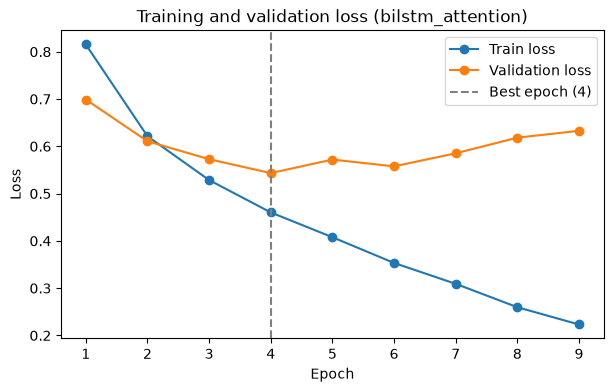

In [7]:
plot_loss_curves(train_losses, val_losses, model_name="bilstm_attention")

Early stopping ends the run once the
validation loss has failed to improve for five consecutive epochs, and the weights of the marked
epoch are the ones restored.

## 5. Confusion matrix

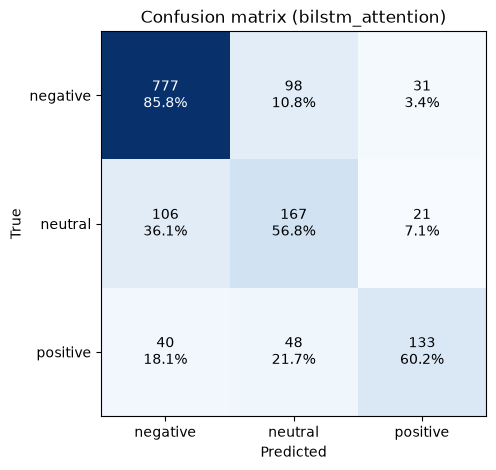

In [8]:
y_true, y_pred = predict(model, test_loader)
plot_confusion_matrix(y_true, y_pred, class_names, model_name="bilstm_attention")